In [1]:
import sys
sys.path.insert(0, '..')

import torch
import os
import wandb
import random
import numpy as np
import torch
from torch import nn
from torch.optim import Adam
from ignite.handlers.param_scheduler import create_lr_scheduler_with_warmup
from torch.utils.data import DataLoader
from datetime import datetime
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from tqdm import tqdm
from matplotlib import cm
import seaborn as sns
import matplotlib.lines as mlines
from sklearn.decomposition import PCA
from openTSNE import TSNE
from PIL import Image
import umap
import torch.nn.functional as F
from scipy.spatial.distance import cdist
import umap.plot
import math
from scipy.stats import norm, rice
import joblib

from core.final.dataset import PSMDataset
from core.final.model import GalSpecNet, MetaModel, Informer, AstroModel
from core.final.trainer import Trainer

/global/home/users/mariia/miniforge3/envs/astro/lib/python3.10/site-packages/ignite/handlers/checkpoint.py:16: DeprecationWarning: `TorchScript` support for functional optimizers is deprecated and will be removed in a future PyTorch release. Consider using the `torch.compile` optimizer instead.
  from torch.distributed.optim import ZeroRedundancyOptimizer
/global/home/users/mariia/miniforge3/envs/astro/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:343: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/global/home/users/mariia/miniforge3/envs/astro/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:343: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc 

In [174]:
def get_model(config):
    if config['mode'] == 'photo':
        model = Informer(config)
    elif config['mode'] == 'spectra':
        model = GalSpecNet(config)
    elif config['mode'] == 'meta':
        model = MetaModel(config)
    else:
        model = AstroModel(config)

    return model

def get_embs(dataloader):
    all_p_emb, all_s_emb, all_m_emb = [], [], []
    all_labels = []
    
    for photometry, photometry_mask, spectra, metadata, labels in tqdm(dataloader):
        photometry, photometry_mask = photometry.to(device), photometry_mask.to(device)
        spectra, metadata = spectra.to(device), metadata.to(device)
    
        with torch.no_grad():
            p_emb, s_emb, m_emb = model.get_embeddings(photometry, photometry_mask, spectra, metadata)
    
            all_p_emb.append(p_emb.cpu())
            all_s_emb.append(s_emb.cpu())
            all_m_emb.append(m_emb.cpu())
            all_labels.append(labels)
    
    all_p_emb = torch.vstack(all_p_emb)
    all_s_emb = torch.vstack(all_s_emb)
    all_m_emb = torch.vstack(all_m_emb)
    all_labels = torch.hstack(all_labels)

    return all_p_emb, all_s_emb, all_m_emb, all_labels

def get_centers(p_emb, s_emb, m_emb, train_labels):
    p_centers, s_centers, m_centers, all_centers = [], [], [], []

    for i in range(10):
        ind = train_labels == i
    
        p_center = p_emb[ind].mean(axis=0)
        p_center = p_center / p_center.norm()
        p_centers.append(p_center)
    
        s_center = s_emb[ind].mean(axis=0)
        s_center = s_center / s_center.norm()
        s_centers.append(s_center)
    
        m_center = m_emb[ind].mean(axis=0)
        m_center = m_center / m_center.norm()
        m_centers.append(m_center)

        all_emb = (p_emb + s_emb + m_emb) / 3
        all_center = all_emb[ind].mean(axis=0)
        all_center = all_center / all_center.norm()
        all_centers.append(all_center)
    
    p_centers = torch.stack(p_centers)
    s_centers = torch.stack(s_centers)
    m_centers = torch.stack(m_centers)
    all_centers = torch.stack(all_centers)

    return p_centers, s_centers, m_centers, all_centers

def plot_obj_umap(dataset, idx, embeddings, targets):
    el = dataset.df.iloc[idx]
    label = target2id[el['target']]
    period = el['org_period']
    l, b = id2lb[el['id']]
    
    photometry = dataset.get_vlc(el['name'])
    photometry = np.vstack(((photometry[:, 0] % period) / period, photometry[:, 1], photometry[:, 2])).T    # fold
    spectra = dataset.readLRSFits(os.path.join(dataset.lamost_spec_dir, el['spec_filename']))

    obj_embedding = embeddings[idx]
    
    fig, axs = plt.subplots(1, 3, figsize=(24, 8))
    axs[0].plot(photometry[:, 0], photometry[:, 1], '.', label='Photometry')
    axs[1].plot(spectra[:, 0], spectra[:, 1], label='Spectra')
    
    for class_name in sorted_classes:
        class_id = target2id[class_name]
        class_mask = targets == class_id
        axs[2].scatter(embeddings[class_mask, 0], embeddings[class_mask, 1], 
                       color=palette[class_id], label=class_name, alpha=1.0, s=marker_size)

    axs[2].scatter(obj_embedding[0], obj_embedding[1], color=palette[targets[idx]], edgecolors='black', alpha=1.0, s=5 * marker_size)
    handles_colors = [mlines.Line2D([], [], color=palette[target2id[class_name]], marker='o', linestyle='None', markersize=8, 
                      label=class_name) for class_name in sorted_classes]
    axs[2].legend(handles=handles_colors, loc='upper right', bbox_to_anchor=(1.15, 1), fontsize=10, title="Classes")
    
    
    plt.suptitle(f'period = {period}    label = {id2target[label]}     idx {idx}    L = {l}    B = {b}    id {el["id"]}')
    plt.tight_layout()
    plt.show()

In [172]:
org_train = pd.read_csv('/home/mariia/AstroML/data/asassn/preprocessed_data/full_lb/spectra_and_v_train.csv')
org_val = pd.read_csv('/home/mariia/AstroML/data/asassn/preprocessed_data/full_lb/spectra_and_v_val.csv')
org_test = pd.read_csv('/home/mariia/AstroML/data/asassn/preprocessed_data/full_lb/spectra_and_v_test.csv')

org_train = org_train[['id', 'l', 'b']]
org_val = org_val[['id', 'l', 'b']]
org_test = org_test[['id', 'l', 'b']]

combined_df = pd.concat([org_train, org_val, org_test])
id2lb = combined_df.set_index('id')[['l', 'b']].T.to_dict('list')

In [3]:
run_id = 'MeriDK/AstroCLIPResults3/2wz4ysvn'
api = wandb.Api()
run = api.run(run_id)
config = run.config
config['use_wandb'] = False

model = get_model(config)
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
model.eval()

weights_path = os.path.join(config['weights_path'] + '-' + run_id.split('/')[-1], f'weights-best.pth')
model.load_state_dict(torch.load(weights_path, weights_only=False))

<All keys matched successfully>

In [74]:
config['file'] = 'preprocessed_data/sub50_lb/spectra_and_v'

train_dataset = PSMDataset(config, split='train')
train_dataloader = DataLoader(train_dataset, batch_size=config['batch_size'], shuffle=False)

val_dataset = PSMDataset(config, split='val')
val_dataloader = DataLoader(val_dataset, batch_size=config['batch_size'], shuffle=False)

test_dataset = PSMDataset(config, split='test')
test_dataloader = DataLoader(test_dataset, batch_size=config['batch_size'], shuffle=False)

train_p_emb, train_s_emb, train_m_emb, train_labels = get_embs(train_dataloader)
val_p_emb, val_s_emb, val_m_emb, val_labels = get_embs(val_dataloader)
test_p_emb, test_s_emb, test_m_emb, test_labels = get_embs(test_dataloader)

p_centers, s_centers, m_centers, all_centers = get_centers(train_p_emb, train_s_emb, train_m_emb, train_labels)

100%|████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:14<00:00,  4.67s/it]


In [105]:
umap = joblib.load('umap.pkl')
train_umap = umap.transform(train_emb)
val_umap = umap.transform(val_emb)
test_umap = umap.transform(test_emb)

In [75]:
train_emb = (train_p_emb + train_s_emb + train_m_emb) / 3
val_emb = (val_p_emb + val_s_emb + val_m_emb) / 3
test_emb = (test_p_emb + test_s_emb + test_m_emb) / 3

In [114]:
def get_distances(p_emb, s_emb, m_emb, emb, labels):
    distances_p = torch.zeros(labels.shape)
    distances_s = torch.zeros(labels.shape)
    distances_m = torch.zeros(labels.shape)
    distances_all = torch.zeros(labels.shape)
    
    for i in range(10):
        ind = labels == i
        
        dist = 1 - p_emb[ind] @ p_centers[i]
        distances_p[ind] = dist
    
        dist = 1 - s_emb[ind] @ s_centers[i]
        distances_s[ind] = dist
    
        dist = 1 - m_emb[ind] @ m_centers[i]
        distances_m[ind] = dist
    
        dist = 1 - emb[ind] @ all_centers[i]
        distances_all[ind] = dist

    return distances_p, distances_s, distances_m, distances_all

In [115]:
train_dist_p, train_dist_s, train_dist_m, train_dist_all = get_distances(train_p_emb, train_s_emb, train_m_emb, train_emb, train_labels)
val_dist_p, val_dist_s, val_dist_m, val_dist_all = get_distances(val_p_emb, val_s_emb, val_m_emb, val_emb, val_labels)
test_dist_p, test_dist_s, test_dist_m, test_dist_all = get_distances(test_p_emb, test_s_emb, test_m_emb, test_emb, test_labels)

In [199]:
def plot_distribution(distances, labels):
    fig, axs = plt.subplots(2, 5, figsize=(20, 10)) 
    axs = axs.flatten() 
    
    for i in range(10):
        data = distances[labels == i]
        axs[i].hist(data, bins=30, density=True, alpha=0.6, color='g', edgecolor='none')
    
        xmin, xmax = axs[i].get_xlim()
        x = np.linspace(xmin, xmax, 100)

        mu, std = norm.fit(data)
        s, loc, scale = rice.fit(data)
        
        p_norm = norm.pdf(x, mu, std)
        axs[i].plot(x, p_norm, 'r', linewidth=2, label=f'Norm: μ={mu:.2f}, σ={std:.2f}')

        p_rice = rice.pdf(x, s, loc=loc, scale=scale)
        axs[i].plot(x, p_rice, 'k', linewidth=2, label=f'Rice: s={s:.2f}, loc={loc:.2f}, scale={scale:.2f}')
        
        axs[i].set_title(f'{train_dataset.id2target[i]}')
        axs[i].legend()
    
    plt.tight_layout()
    plt.show()

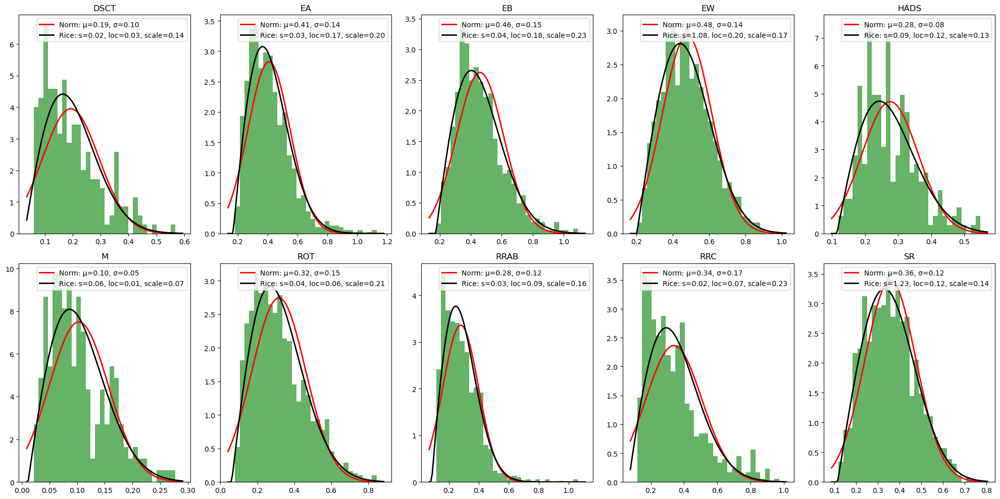

In [200]:
plot_distribution(train_dist_p, train_labels)

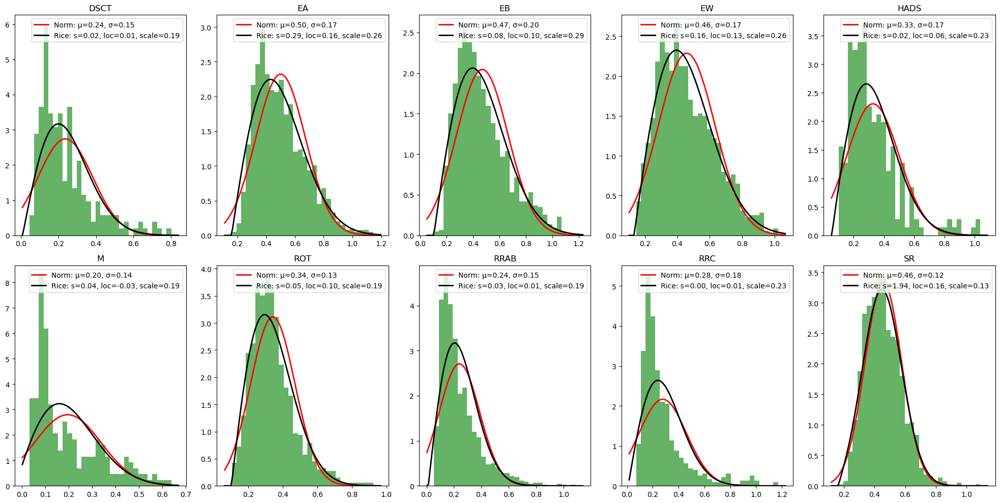

In [201]:
plot_distribution(train_dist_s, train_labels)

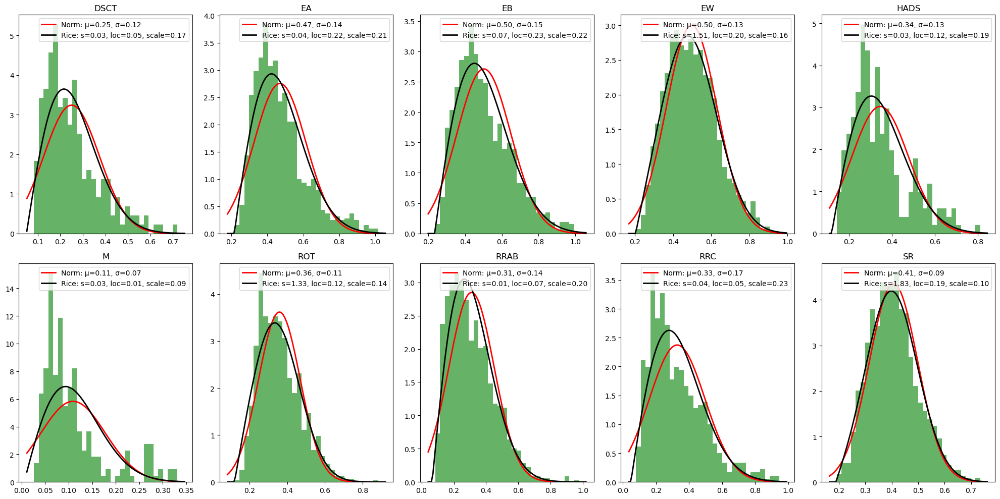

In [202]:
plot_distribution(train_dist_m, train_labels)

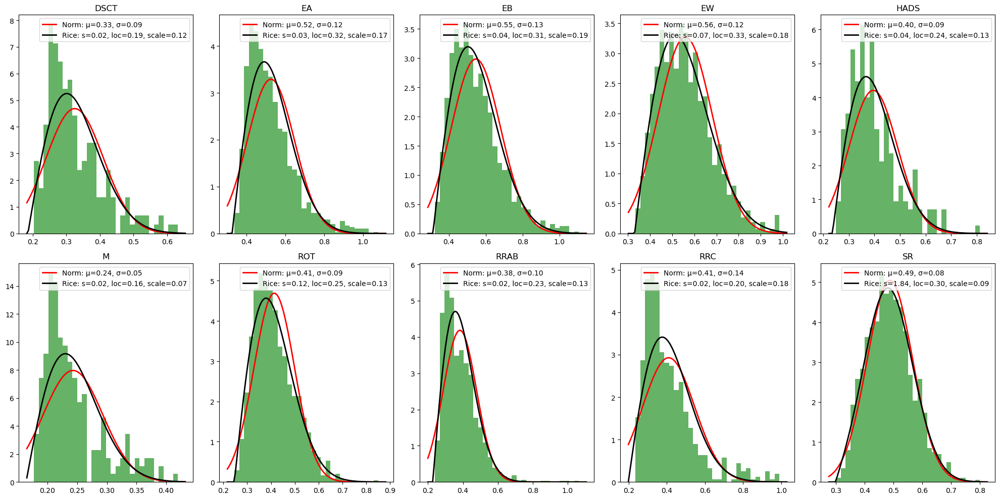

In [203]:
plot_distribution(train_dist_all, train_labels)

In [63]:
class_freq = test_dataset.df['target'].value_counts()
sorted_classes = class_freq.index

id2target = test_dataset.id2target
target2id = test_dataset.target2id

palette = sns.color_palette("Spectral", len(id2target))
palette[3], palette[-4] = palette[-4], palette[3] 
palette[1], palette[-2] = palette[-2], palette[1] 
marker_size = 12

In [211]:
def plot_distribution_one_graph(distances, labels):    
    info = {}

    for class_name in sorted_classes:
        class_id = target2id[class_name]
        data = distances[labels == class_id]
        
        xmin, xmax = distances.min(), distances.max()
        x = np.linspace(xmin, xmax, 100)
        
        s, loc, scale = rice.fit(data)
        p_rice = rice.pdf(x, s, loc=loc, scale=scale)
        percentile_99 = rice.ppf(0.99, s, loc=loc, scale=scale)
        info[class_name] = {'s': s, 'loc': loc, 'scale': scale, 'percentile_99': percentile_99}

        plt.plot(x, p_rice, linewidth=1, color=palette[class_id], label=f'{class_name}')
        plt.axvline(percentile_99, color=palette[class_id], linestyle='--', linewidth=1)
        plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    return info

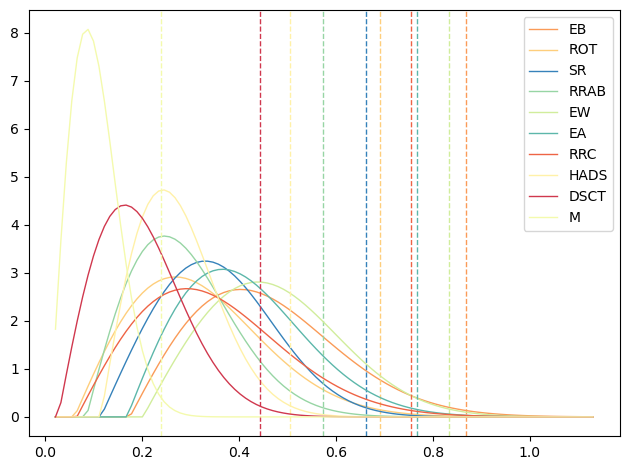

In [212]:
info_p = plot_distribution_one_graph(train_dist_p, train_labels)

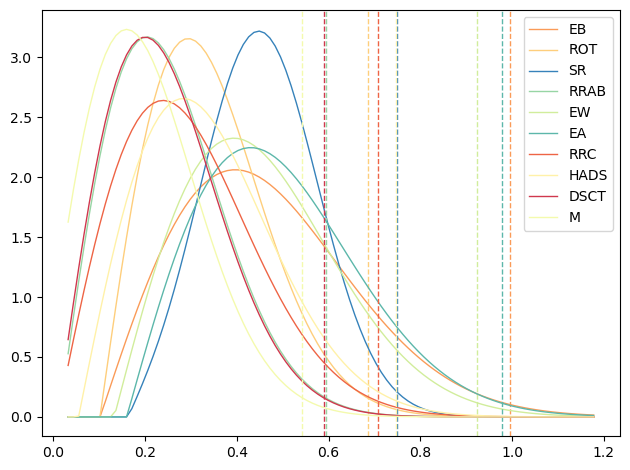

In [213]:
info_s = plot_distribution_one_graph(train_dist_s, train_labels)

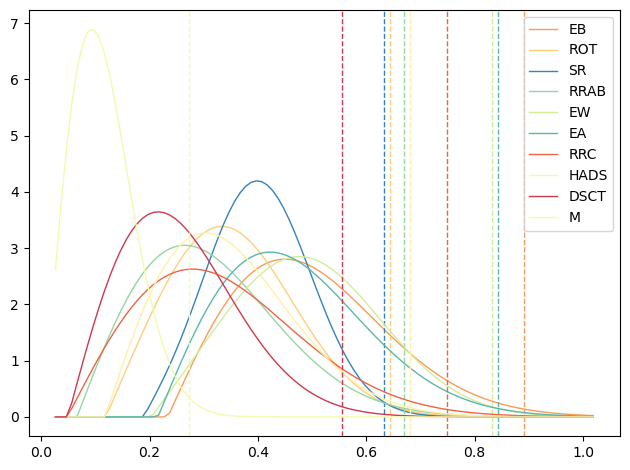

In [214]:
info_m = plot_distribution_one_graph(train_dist_m, train_labels)

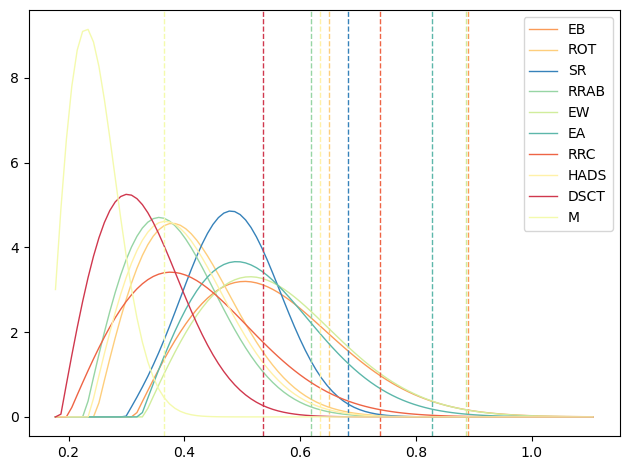

In [215]:
info_all = plot_distribution_one_graph(train_dist_all, train_labels)

In [220]:
def get_out_masks(distances_p, distances_s, distances_m, distances_all, labels):
    mis_p = torch.zeros(labels.shape, dtype=torch.bool)
    mis_s = torch.zeros(labels.shape, dtype=torch.bool)
    mis_m = torch.zeros(labels.shape, dtype=torch.bool)
    mis_all = torch.zeros(labels.shape, dtype=torch.bool)
    
    for i in range(10):
        ind = labels == i
        
        mis_p[ind] = distances_p[ind] > info_p[id2target[i]]['percentile_99']
        mis_s[ind] = distances_s[ind] > info_s[id2target[i]]['percentile_99']    
        mis_m[ind] = distances_m[ind] > info_m[id2target[i]]['percentile_99']    
        mis_all[ind] = distances_all[ind] > info_all[id2target[i]]['percentile_99']

    return mis_p, mis_s, mis_m, mis_all

In [221]:
train_mis_p, train_mis_s, train_mis_m, train_mis_all = get_out_masks(train_dist_p, train_dist_s, train_dist_m, train_dist_all, train_labels)
val_mis_p, val_mis_s, val_mis_m, val_mis_all = get_out_masks(val_dist_p, val_dist_s, val_dist_m, val_dist_all, val_labels)
test_mis_p, test_mis_s, test_mis_m, test_mis_all = get_out_masks(test_dist_p, test_dist_s, test_dist_m, test_dist_all, test_labels)

In [222]:
train_mis_p.sum(), train_mis_s.sum(), train_mis_m.sum(), train_mis_all.sum()

(tensor(149), tensor(184), tensor(156), tensor(181))

In [223]:
(train_mis_p & train_mis_s & train_mis_m).sum()

tensor(40)

In [224]:
val_mis_p.sum(), val_mis_s.sum(), val_mis_m.sum(), val_mis_all.sum()

(tensor(23), tensor(39), tensor(26), tensor(28))

In [225]:
(val_mis_p & val_mis_s & val_mis_m).sum()

tensor(8)

In [226]:
test_mis_p.sum(), test_mis_s.sum(), test_mis_m.sum(), test_mis_all.sum()

(tensor(14), tensor(33), tensor(18), tensor(21))

In [227]:
(test_mis_p & test_mis_s & test_mis_m).sum()

tensor(2)

In [228]:
train_idx = torch.arange(len(train_dataset))[(train_mis_p & train_mis_s & train_mis_m)]
val_idx = torch.arange(len(val_dataset))[(val_mis_p & val_mis_s & val_mis_m)]
test_idx = torch.arange(len(test_dataset))[(test_mis_p & test_mis_s & test_mis_m)]

In [229]:
train_idx

tensor([ 403,  435,  470,  488,  494,  531,  574,  610,  762, 1259, 1307, 2152,
        2276, 3170, 3252, 3472, 3708, 3868, 3961, 4167, 4396, 4409, 4421, 4485,
        4620, 4704, 5035, 5105, 5189, 5312, 5337, 6209, 7218, 7411, 7660, 7894,
        7994, 8161, 8179, 8386])

In [230]:
val_idx

tensor([ 61,  84,  91, 372, 664, 669, 737, 904])

In [231]:
test_idx

tensor([60, 71])

In [232]:
train_idx_all = torch.arange(len(train_dataset))[train_mis_all]
val_idx_all = torch.arange(len(val_dataset))[val_mis_all]
test_idx_all = torch.arange(len(test_dataset))[test_mis_all]

In [233]:
umap_train_idx = joblib.load('train_idx.pkl')
umap_val_idx = joblib.load('val_idx.pkl')
umap_test_idx = joblib.load('test_idx.pkl')

/global/home/users/mariia/miniforge3/envs/astro/lib/python3.10/site-packages/torch/storage.py:414: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(io.BytesIO

In [234]:
train_intersection = torch.tensor([el for el in train_idx_all if el in umap_train_idx])
train_diff = torch.tensor([el for el in train_idx_all if el not in umap_train_idx])

val_intersection = torch.tensor([el for el in val_idx_all if el in umap_val_idx])
val_diff = torch.tensor([el for el in val_idx_all if el not in umap_val_idx])

test_intersection = torch.tensor([el for el in test_idx_all if el in umap_test_idx])
test_diff = torch.tensor([el for el in test_idx_all if el not in umap_test_idx])

In [235]:
len(train_intersection), len(val_intersection), len(test_intersection)

(91, 22, 11)

In [236]:
train_diff

tensor([  26,  444,  449,  491,  496,  543,  594,  614,  702,  762,  771,  773,
         901,  943,  996, 1067, 1125, 1210, 1255, 1259, 1364, 1562, 1679, 1957,
        2180, 2395, 2426, 2547, 2689, 2746, 2901, 3055, 3167, 3170, 3198, 3252,
        3350, 3550, 3843, 3889, 3896, 4046, 4195, 4237, 4293, 4400, 4402, 4405,
        4421, 4462, 4463, 4589, 4594, 4597, 4598, 4603, 4612, 4728, 4806, 4826,
        4860, 5078, 5309, 5313, 5337, 5411, 5576, 5702, 5728, 5864, 6039, 6276,
        6360, 6866, 7081, 7387, 7651, 7758, 7763, 7767, 7894, 7929, 7931, 8044,
        8049, 8139, 8147, 8179, 8414, 8505])

In [237]:
val_diff

tensor([ 73,  88, 144, 569, 590, 824])

In [238]:
test_diff

tensor([  4,  51,  69, 372, 471, 561, 575, 578, 639, 737])

# New obj from train set based on avg embedding distances > 99th percentile

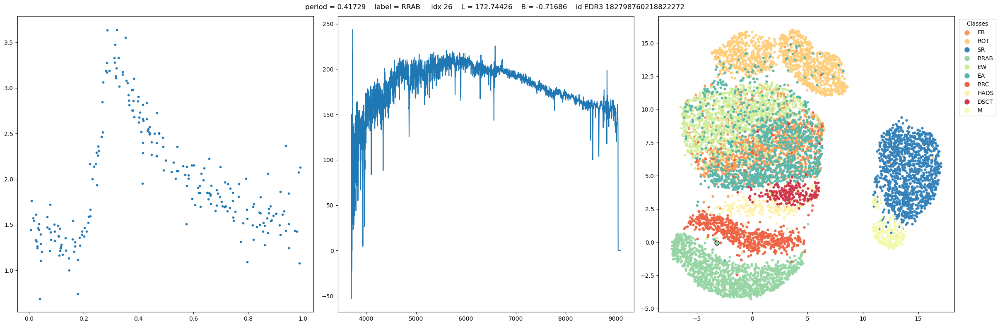

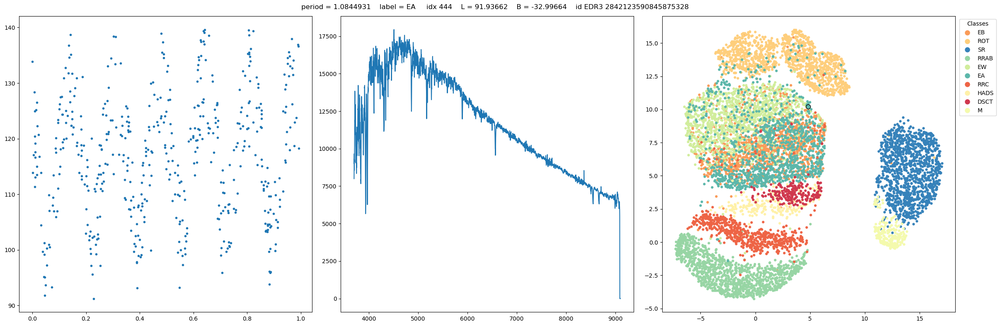

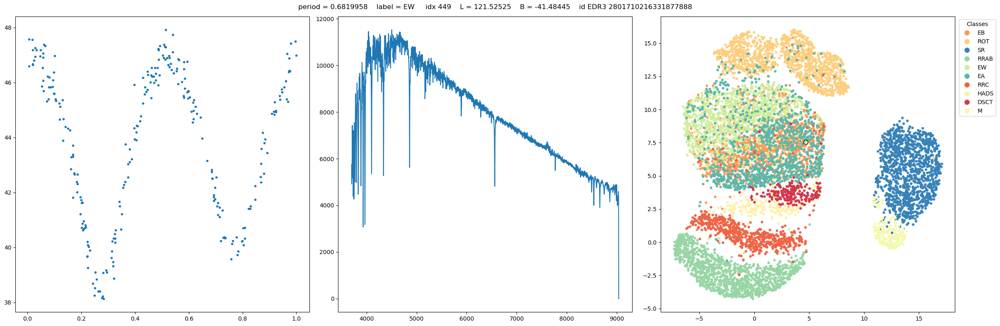

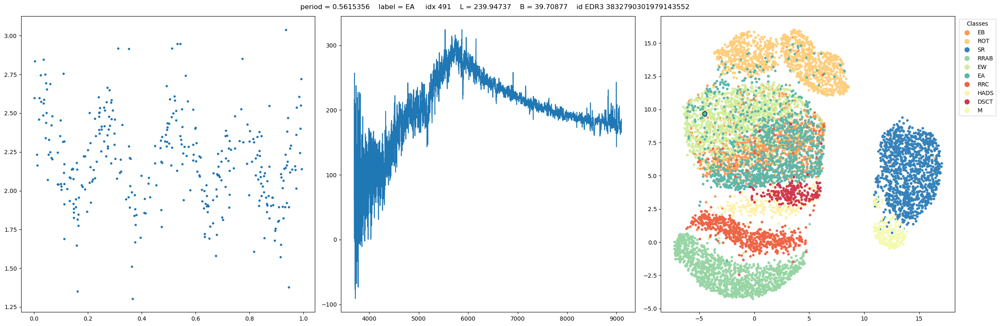

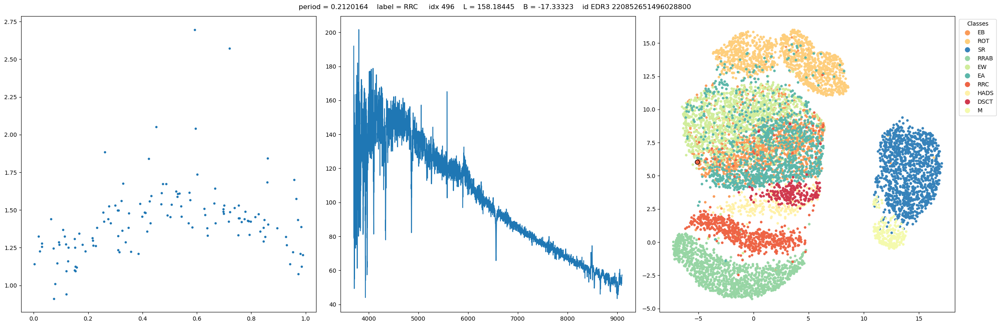

...

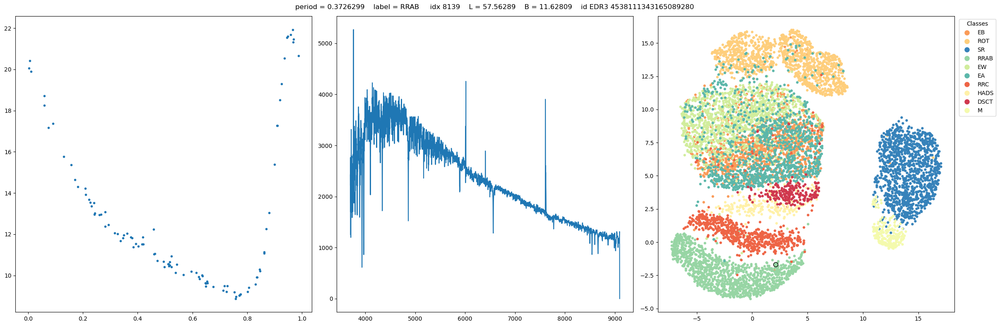

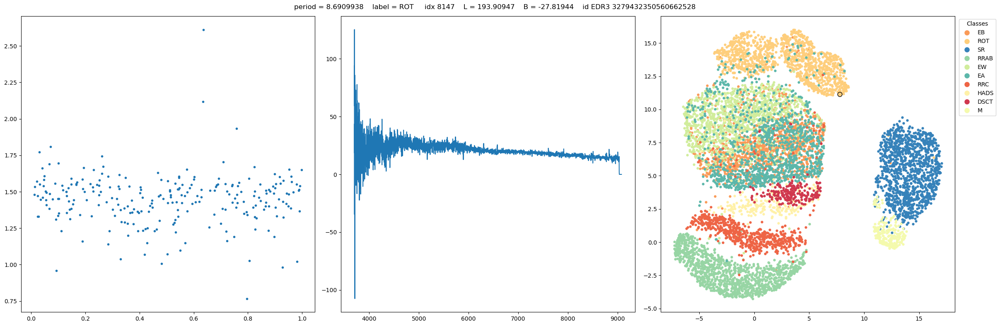

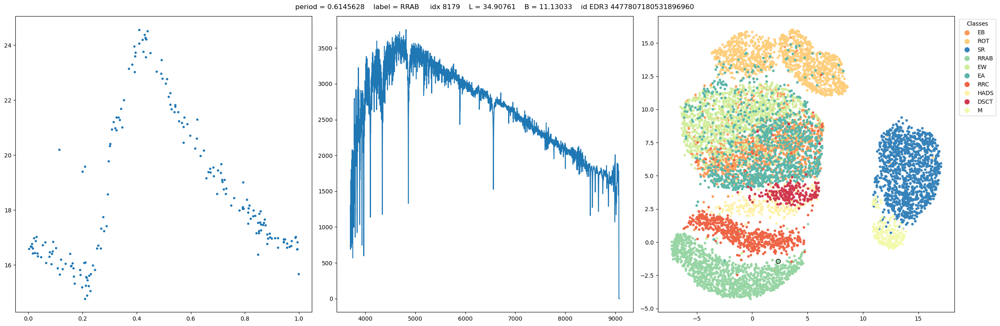

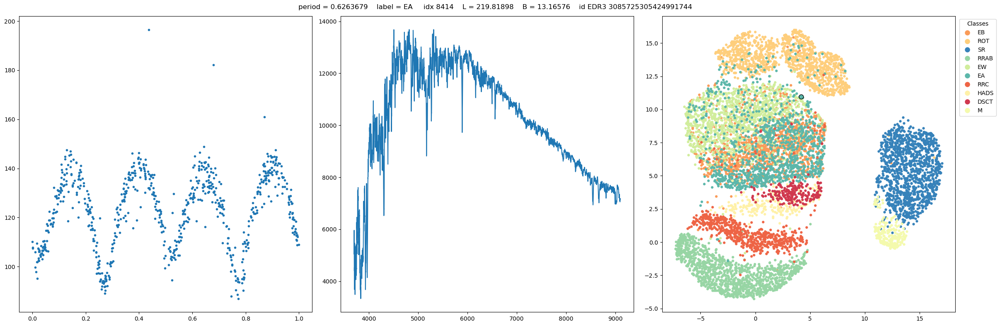

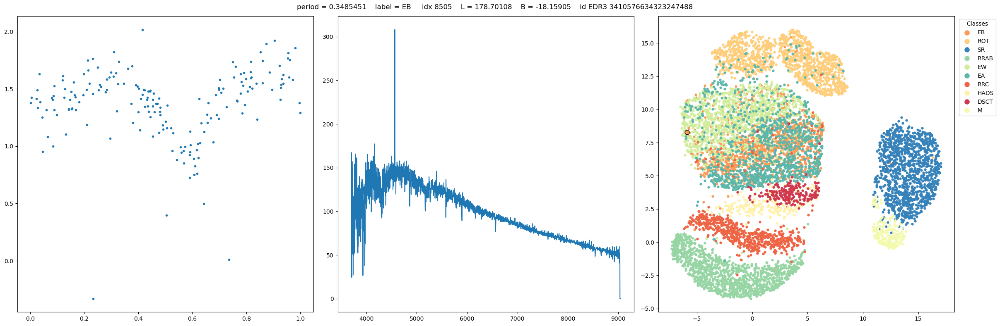

In [239]:
for el in train_diff:
    plot_obj_umap(train_dataset, el.item(), train_umap, train_labels)

# New obj from VAL set based on avg embedding distances > 99th percentile

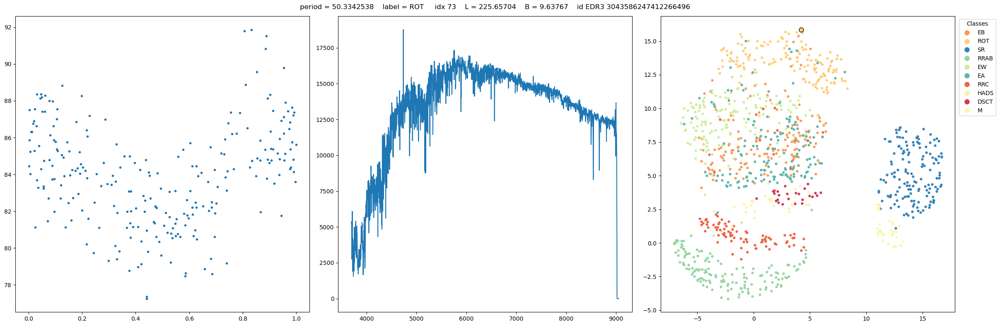

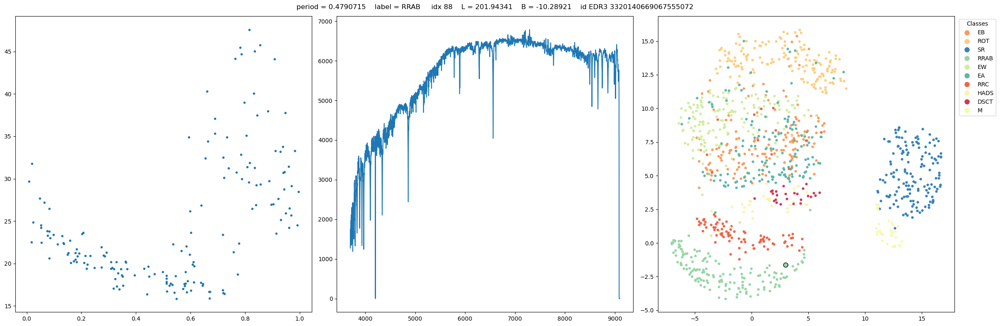

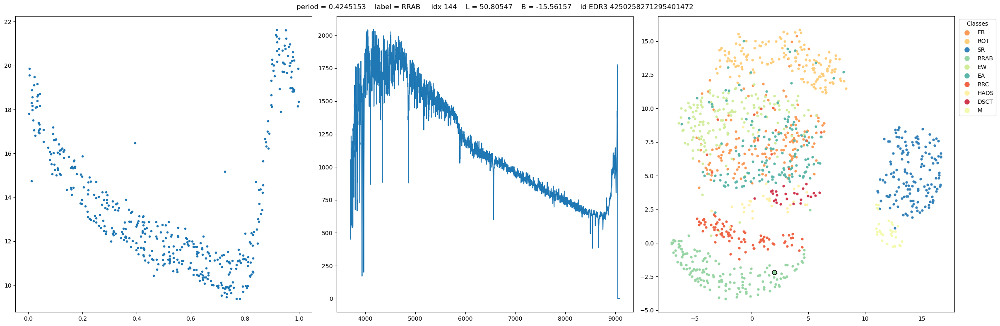

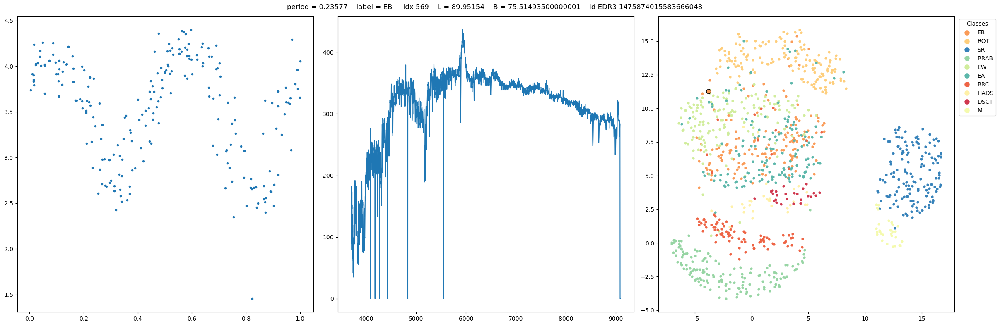

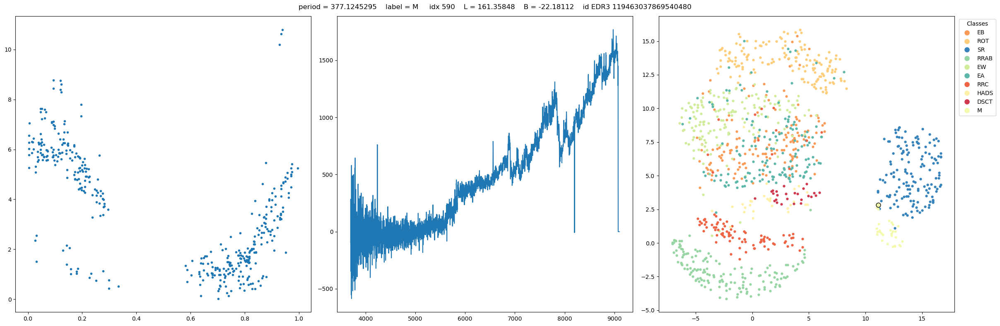

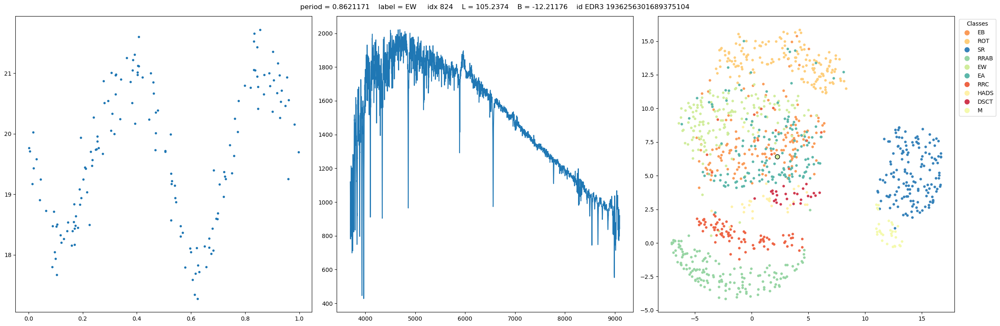

In [240]:
for el in val_diff:
    plot_obj_umap(val_dataset, el.item(), val_umap, val_labels)

# New obj from TEST set based on avg embedding distances > 99th percentile

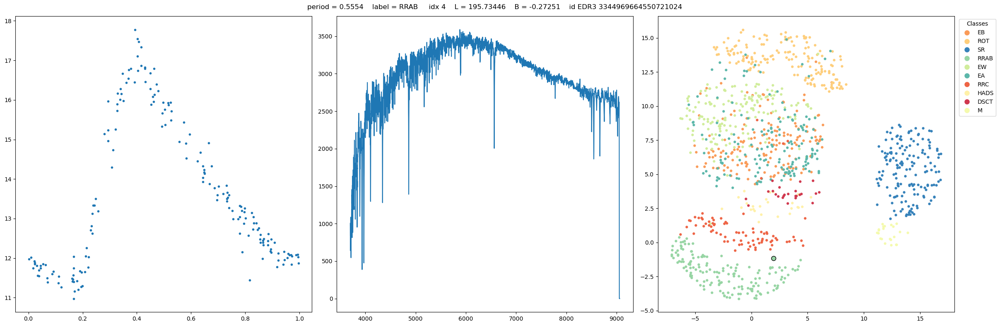

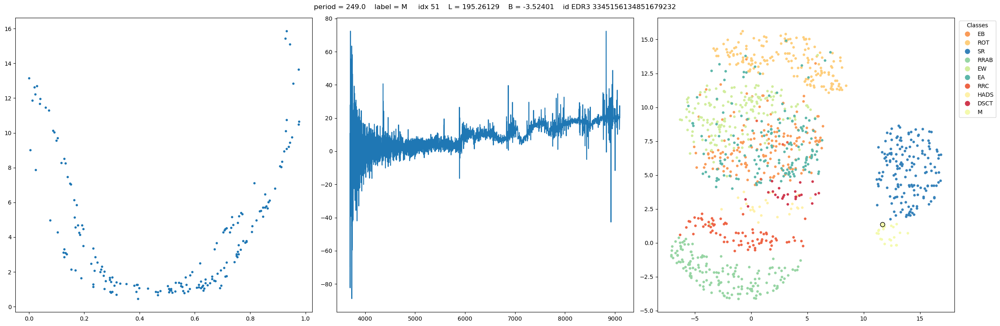

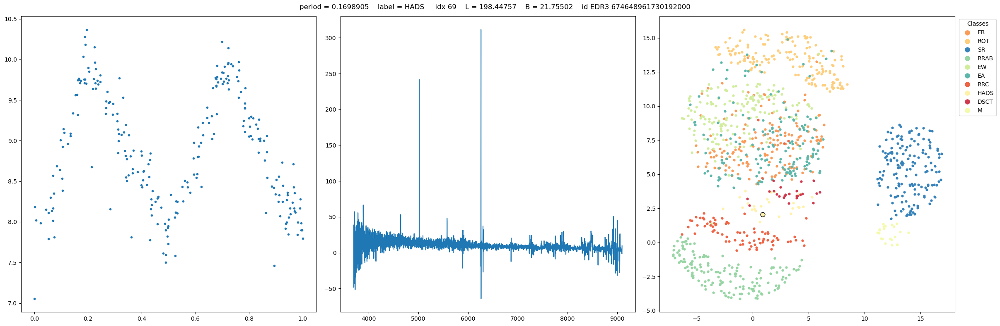

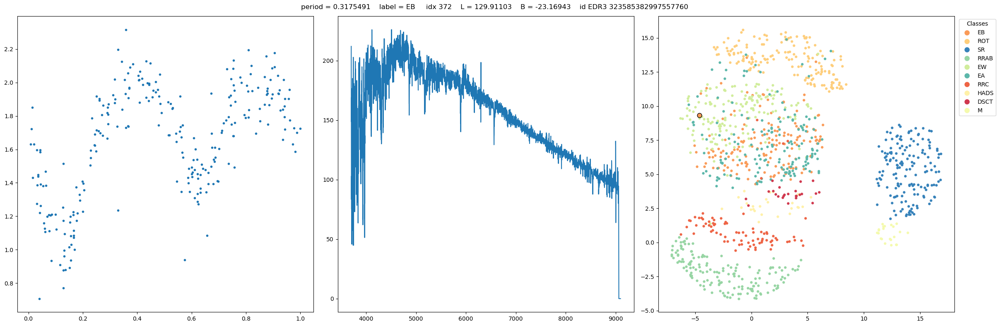

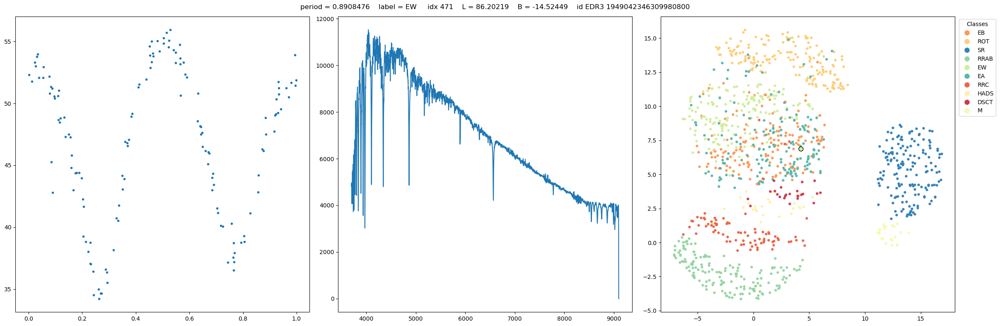

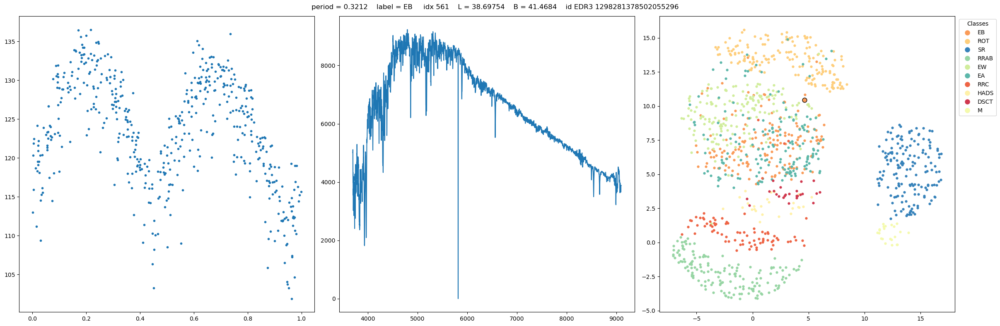

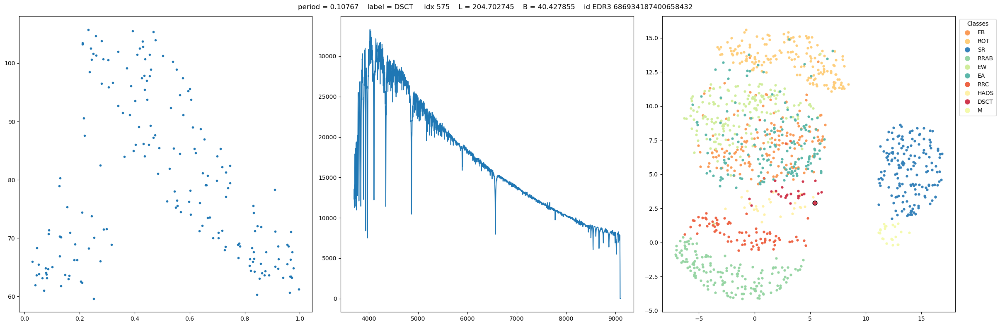

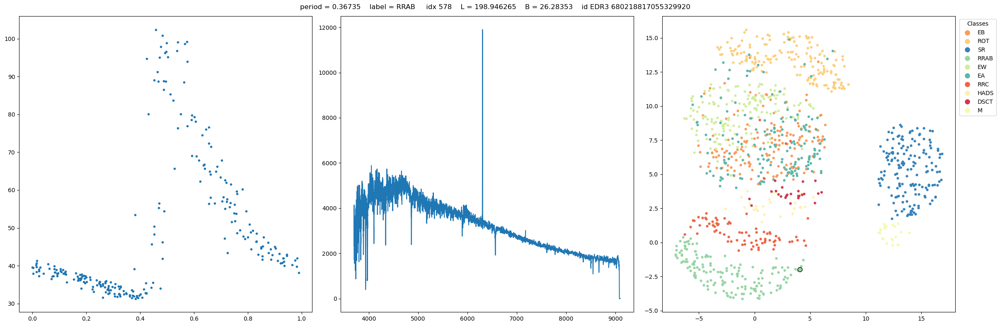

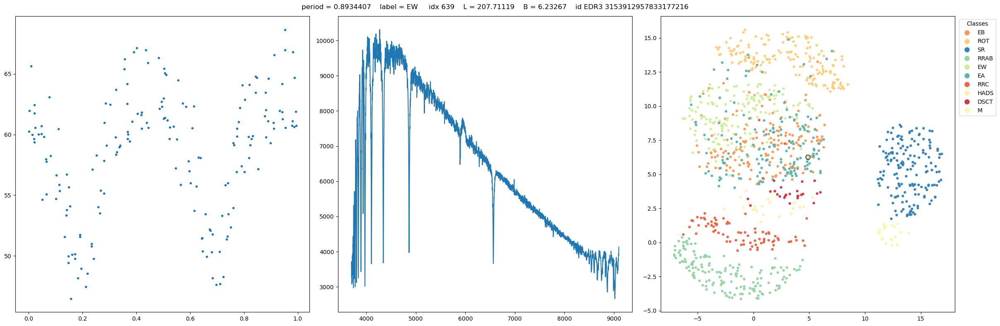

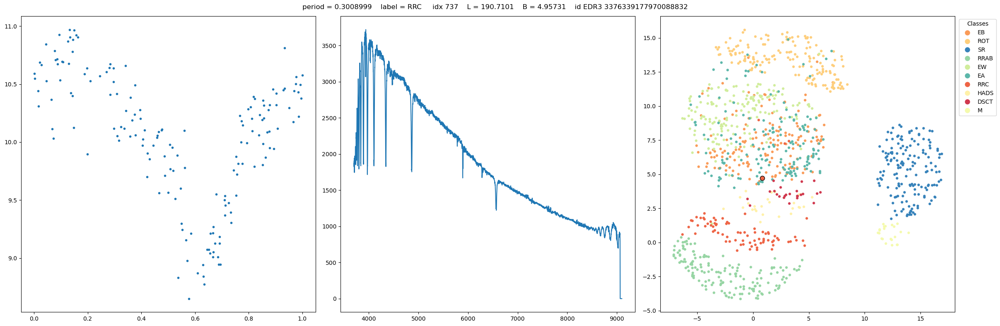

In [241]:
for el in test_diff:
    plot_obj_umap(test_dataset, el.item(), test_umap, test_labels)

# Train all modalities dist > 99th percentile

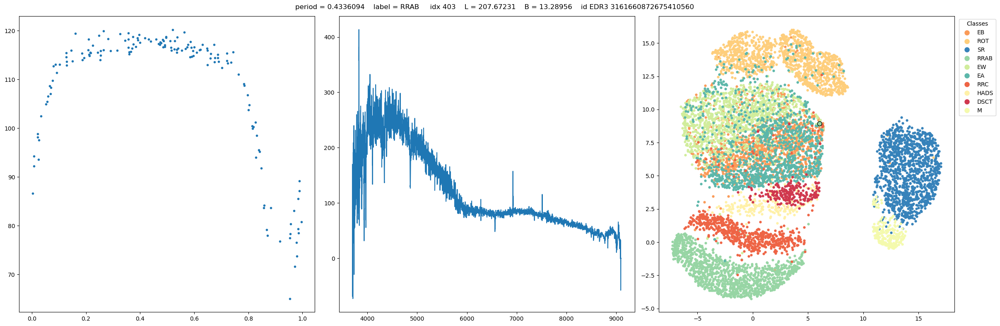

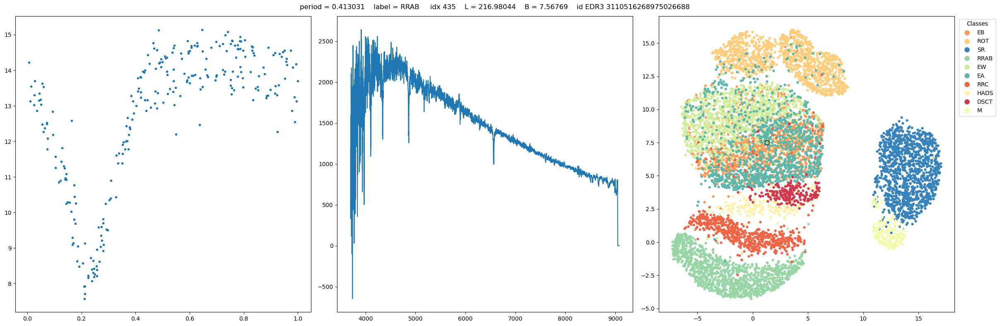

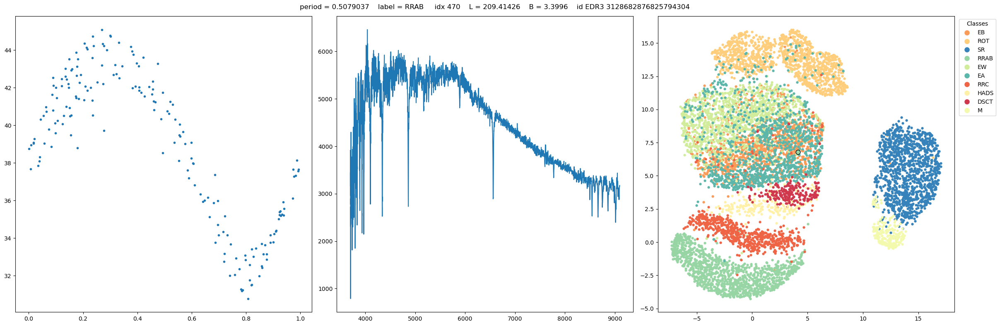

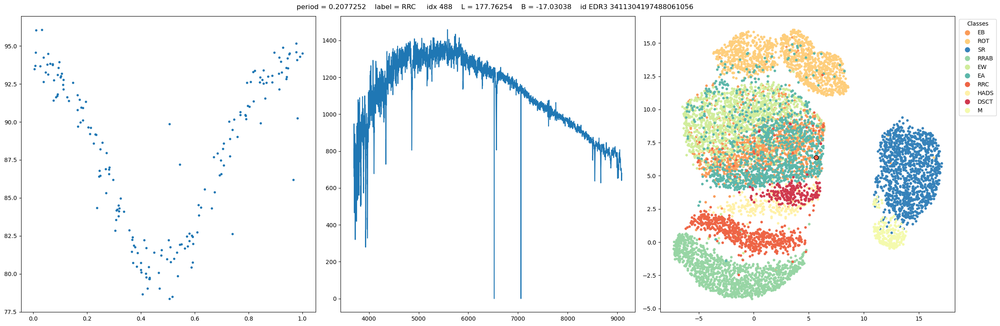

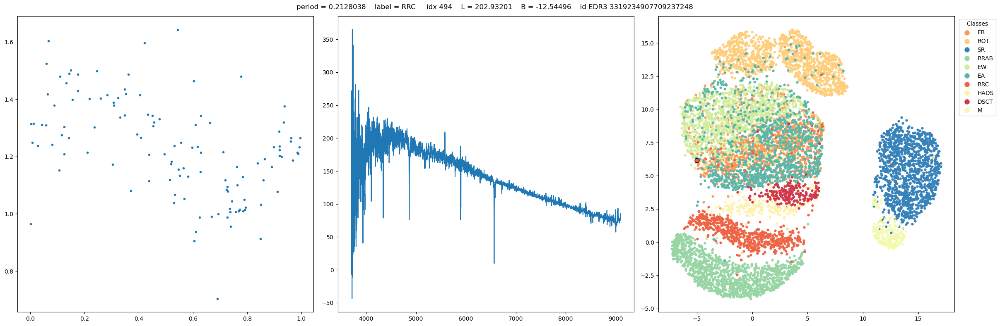

...

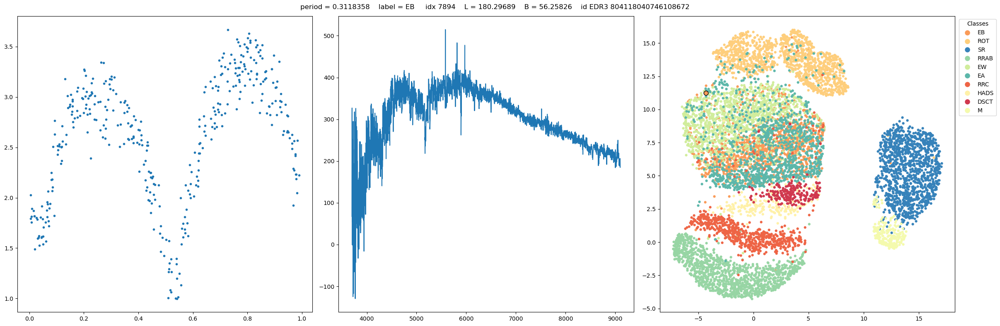

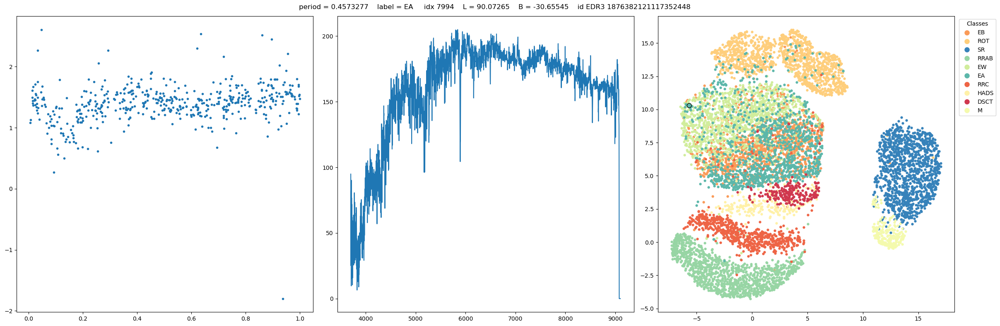

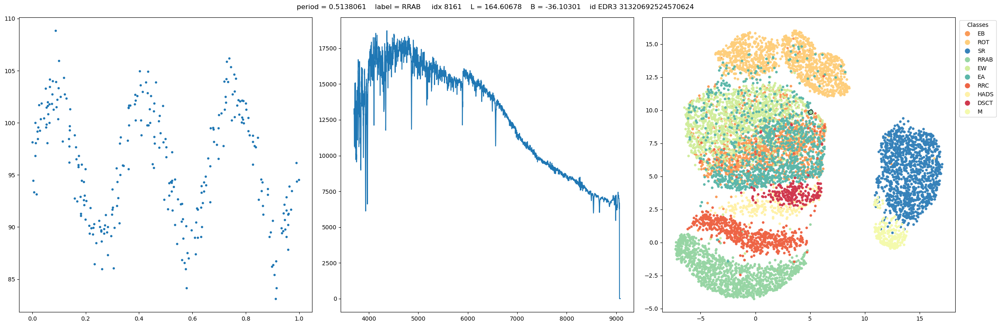

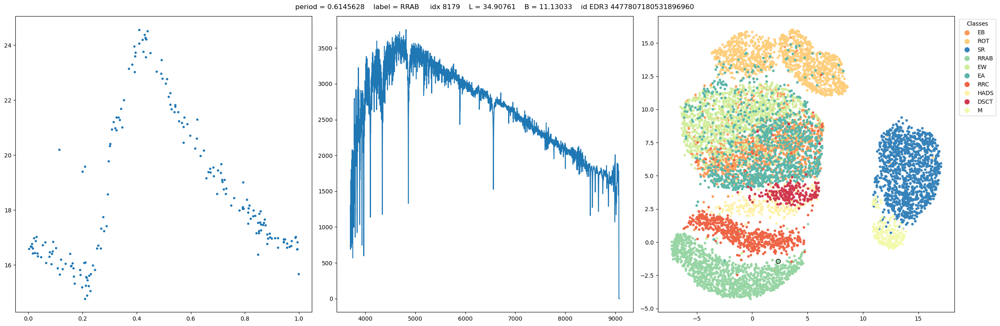

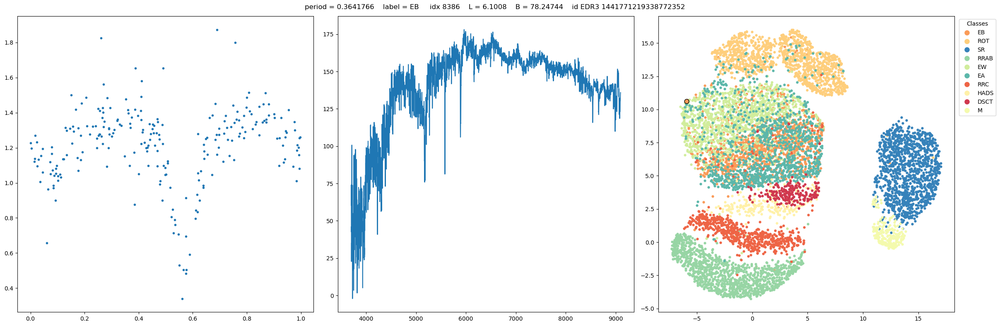

In [245]:
for el in train_idx:
    plot_obj_umap(train_dataset, el.item(), train_umap, train_labels)

# Val all modalities dist > 99th percentile

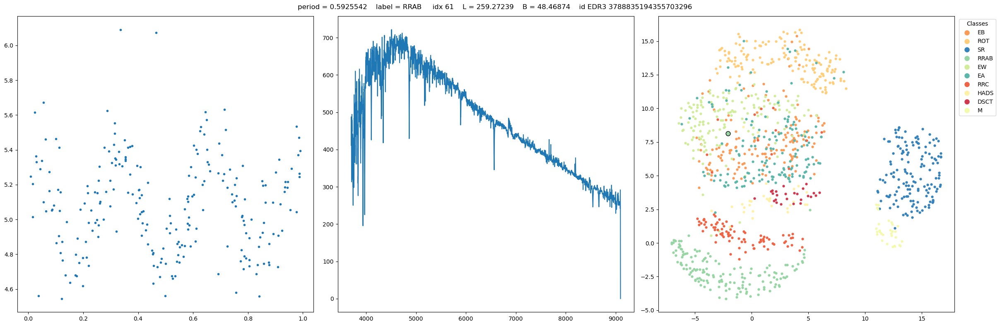

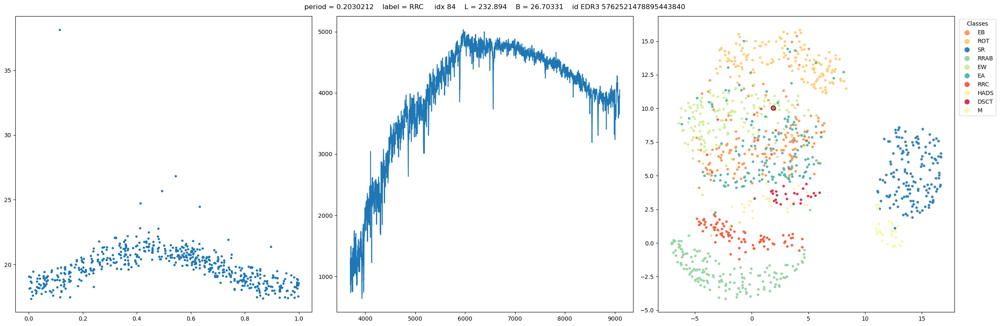

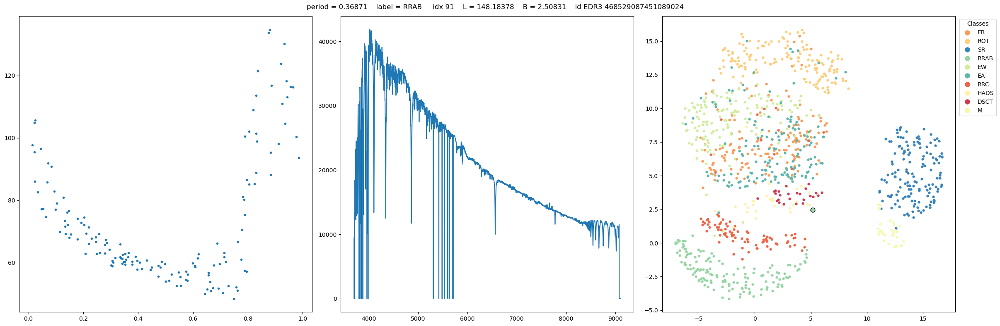

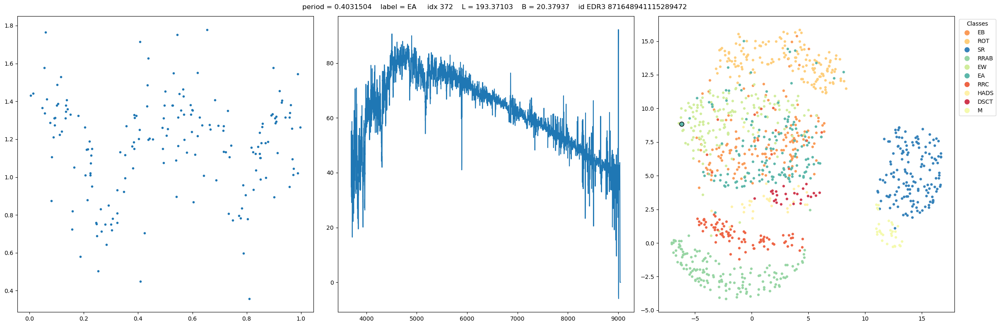

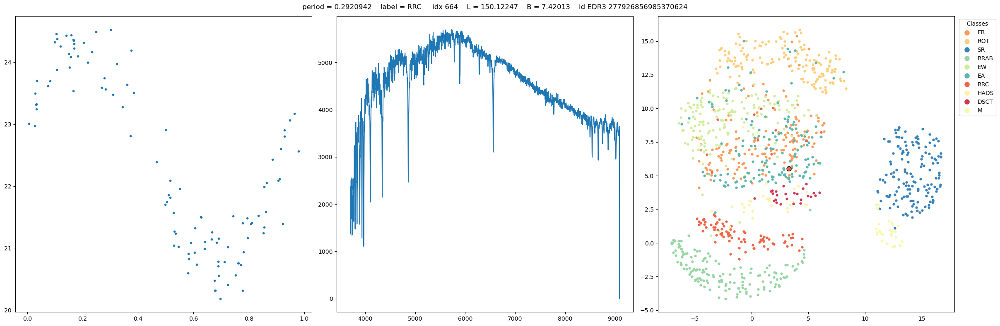

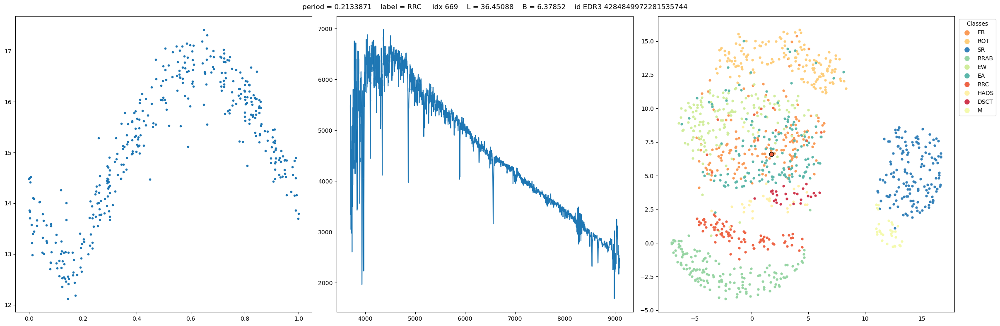

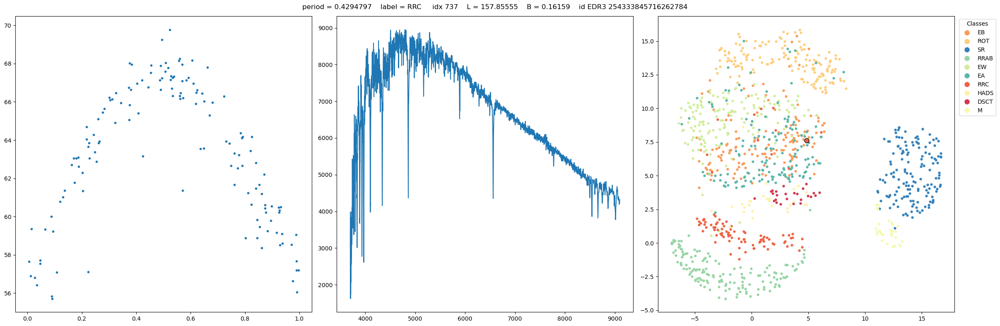

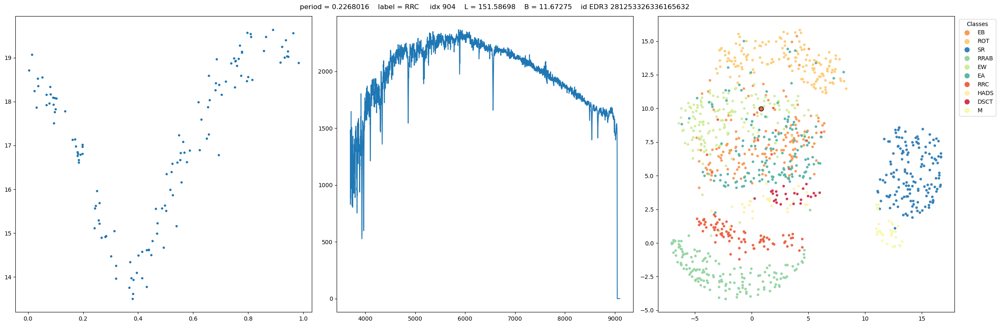

In [246]:
for el in val_idx:
    plot_obj_umap(val_dataset, el.item(), val_umap, val_labels)

# Test all modalities dist > 99th percentile

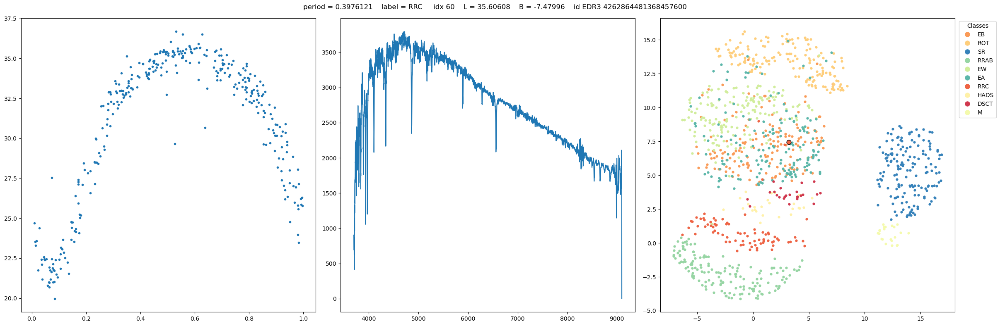

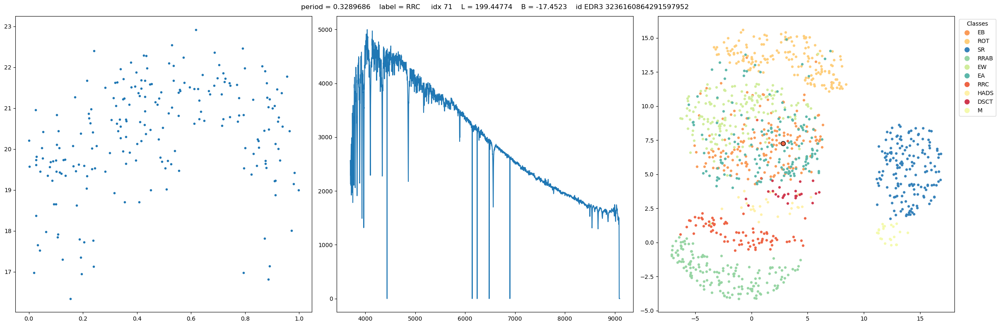

In [247]:
for el in test_idx:
    plot_obj_umap(test_dataset, el.item(), test_umap, test_labels)

In [90]:
pred_labels_p = torch.argmax(train_p_emb[mis] @ p_centers.T, axis=1)
true_labels_p = train_labels[mis]

In [91]:
pred_labels_p == true_labels_p

tensor([False, False, False,  True, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False,  True, False, False,
         True,  True,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False,  True, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
         True, False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False,  True, False, False, False, False, False, False,
        False, False, False,  True,  True, False, False, False, 

In [98]:
torch.arange(len(train_p_emb))[mis]

tensor([  430,   457,   753,   781,   812,   818,   881,   891,   894,   907,
          916,   931,   940,   952,   953,   989,  1011,  1027,  1042,  1052,
         1054,  1106,  1112,  1176,  1187,  1293,  1301,  1315,  1362,  1386,
         1455,  1479,  1491,  1510,  1715,  1726,  1875,  1895,  1994,  2025,
         2211,  2370,  2557,  2600,  2790,  3268,  3438,  3493,  3574,  3595,
         3677,  3886,  3985,  4223,  4286,  4287,  4395,  4676,  4757,  4831,
         4836,  5011,  5648,  5926,  5989,  6193,  6222,  6329,  6435,  6539,
         6702,  6857,  7170,  7627,  7636,  7656,  7763,  8272,  8522,  8660,
         8938,  8941,  8952,  8956,  8957,  8972,  8988,  9067,  9108,  9218,
         9285,  9452,  9493,  9675,  9732,  9833,  9841, 10037, 10049, 10200,
        10281, 10299, 10751, 11371, 11420, 12114, 12248, 12563, 12755, 14814,
        15059, 15170, 15260, 15441, 15494, 15506, 15573, 15796, 15887, 15962,
        15994, 16027, 16039, 16166, 16300, 16343, 16447, 16449, 

In [111]:
i = 781
train_p_emb[i] @ p_centers.T

tensor([0.0079, 0.1358, 0.2115, 0.2095, 0.0508, 0.1212, 0.0486, 0.3084, 0.2576,
        0.1472])

In [107]:
train_labels[i]

tensor(7)

In [109]:
info_p[id2target[7]]

{'mu': 0.27997926, 'std': 0.11995941}

In [112]:
0.27997926 + 3 * 0.11995941

0.63985749

In [114]:
el = train_dataset.df.iloc[i]
label = target2id[el['target']]
photometry = train_dataset.get_vlc(el['name'])
spectra = train_dataset.readLRSFits(os.path.join(train_dataset.lamost_spec_dir, el['spec_filename']))
period = el['org_period']

NameError: name 'target2id' is not defined